### Import Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

### Obtain Dataset

In [11]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()  

In [12]:
print("Training data shape:", x_train.shape, y_train.shape)
print("Testing data shape:", x_test.shape, y_test.shape)

Training data shape: (60000, 28, 28) (60000,)
Testing data shape: (10000, 28, 28) (10000,)


In [13]:
# x_train 

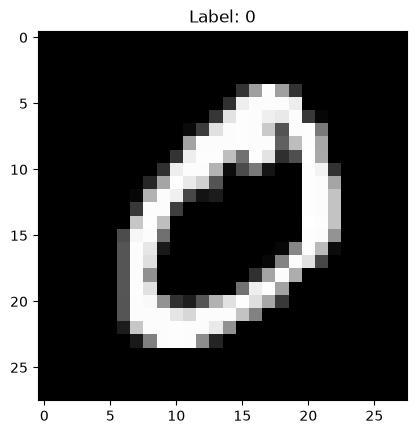

In [14]:
# Display a sample image
plt.imshow(x_train[1], cmap="gray")
plt.title(f"Label: {y_train[1]}")
#plt.axis("off")
plt.show()

### Data Preprocessing

In [15]:
# Normalisation
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

In [16]:
# Flatten the images for the fully connected layers
x_train = x_train.reshape(-1, 28 * 28)
x_test  = x_test.reshape(-1, 28 * 28)

print("New shape of training data:", x_train.shape)
print("New shape of test data:", x_test.shape)

New shape of training data: (60000, 784)
New shape of test data: (10000, 784)


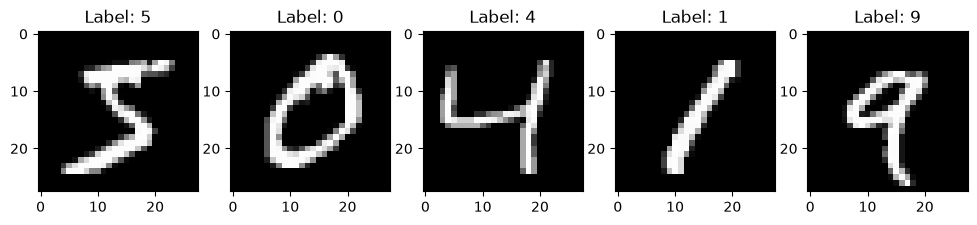

In [17]:
# Display sample images
fig, axes = plt.subplots(1, 5, figsize=(12, 4))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    # ax.axis("off")
plt.show()

### Simple FNN

In [18]:
input_shape = x_train.shape[1]  # 784 for 28x28 images

In [ ]:
keras.utils.set_random_seed(42)

In [19]:
# Define a simple fully connected neural network
model1 = keras.Sequential([
                            layers.Dense(32, activation="relu", input_shape=(input_shape,)), # Single hidden layer
                            layers.Dense(10, activation="softmax") # Output layer for classification
                            ])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
# Compile the model
model1.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [21]:
history1 = model1.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 380us/step - accuracy: 0.8996 - loss: 0.3556 - val_accuracy: 0.9355 - val_loss: 0.2193
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 345us/step - accuracy: 0.9433 - loss: 0.1953 - val_accuracy: 0.9504 - val_loss: 0.1692
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 348us/step - accuracy: 0.9556 - loss: 0.1525 - val_accuracy: 0.9531 - val_loss: 0.1585
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 354us/step - accuracy: 0.9623 - loss: 0.1262 - val_accuracy: 0.9612 - val_loss: 0.1295
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 368us/step - accuracy: 0.9677 - loss: 0.1093 - val_accuracy: 0.9647 - val_loss: 0.1185


In [22]:
# Evaluate the model
test_loss, test_acc = model1.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 311us/step - accuracy: 0.9647 - loss: 0.1185
Test Accuracy: 0.9647


### Deeper FNN

In [23]:
# Define a deeper fully connected neural network
model2 = keras.Sequential([
                            layers.Dense(128, activation="relu", input_shape=(784,)), # First hidden layer
                            layers.Dense(64, activation="relu"), # Second hidden layer
                            layers.Dense(32, activation="relu"), # Third hidden layer
                            layers.Dense(10, activation="softmax") # Output layer
                        ])

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
# Compile model
model2.compile(optimizer="adam",
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])

In [25]:
# Train the model
history2 = model2.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 719us/step - accuracy: 0.9227 - loss: 0.2608 - val_accuracy: 0.9552 - val_loss: 0.1415
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 645us/step - accuracy: 0.9668 - loss: 0.1072 - val_accuracy: 0.9631 - val_loss: 0.1161
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 639us/step - accuracy: 0.9754 - loss: 0.0763 - val_accuracy: 0.9744 - val_loss: 0.0841
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 641us/step - accuracy: 0.9816 - loss: 0.0577 - val_accuracy: 0.9755 - val_loss: 0.0901
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 636us/step - accuracy: 0.9853 - loss: 0.0475 - val_accuracy: 0.9715 - val_loss: 0.1022


In [26]:
# Evaluate the model
test_loss, test_acc = model2.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 319us/step - accuracy: 0.9715 - loss: 0.1022
Test Accuracy: 0.9715


Text(0.5, 1.0, 'Training & Validation Accuracy')

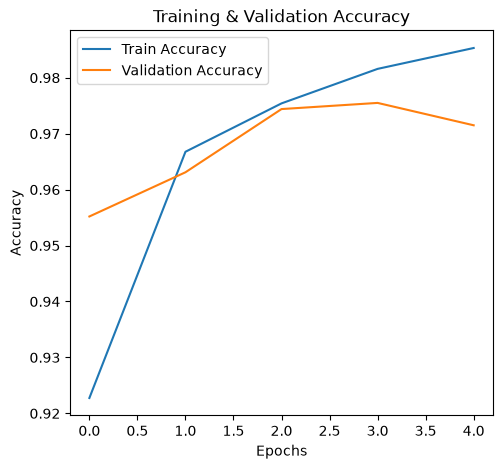

In [27]:
# Plot training history
plt.figure(figsize=(12, 5))
# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Training & Validation Accuracy")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 288us/step


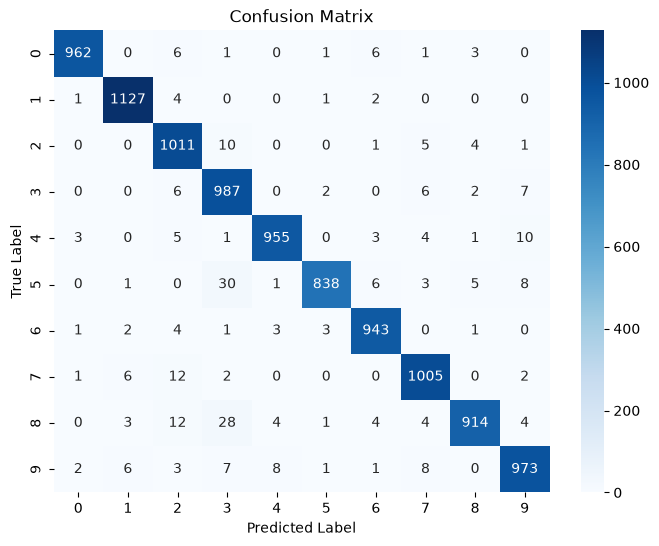

In [29]:
import seaborn as sns

# Generate predictions
y_pred = model2.predict(x_test).argmax(axis=1)
# Compute confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

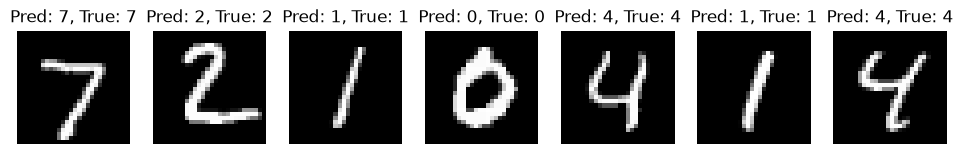

In [33]:
# Display predictions on test images
fig, axes = plt.subplots(1, 7, figsize=(12, 4))
for i, ax in enumerate(axes):
    ax.imshow(x_test[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"Pred: {y_pred[i]}, True: {y_test[i]}")
    ax.axis("off")
plt.show()